# Hafta 3 · Regresyon ve Gradyan İniş

**Yapay Zekâya Giriş — Laboratuvar Defteri**  
Dr. Seda Bayat Toksöz · Iğdır Üniversitesi · 2026–2027 Güz

Bu defterde Çözümlü Örnek 3.1–3.5'teki doğrusal regresyon hesaplarını scikit-learn, normal denklem ve sıfırdan yazılmış gradyan inişle tekrarlayacak; öğrenme oranının etkisini gözlemleyeceksiniz.

Hücreleri yukarıdan aşağıya sırayla çalıştırın (**Shift + Enter**). Parametreleri değiştirip sonucun nasıl değiştiğini gözlemleyin.

In [1]:
# Grafik ayarları (ders notlarıyla aynı renk paleti)
import matplotlib.pyplot as plt
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#0072B2", "#D55E00", "#009E73", "#E69F00", "#56B4E9", "#CC79A7"]),
})

## 1. scikit-learn ile doğrusal regresyon (Çözümlü Örnek 3.1 ve 3.3)

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

x = np.array([1, 2, 3, 4, 5], dtype=float)
y = np.array([2, 4, 5, 4, 5], dtype=float)

# 1) Hazır kütüphane ile (en küçük kareler)
model = LinearRegression().fit(x.reshape(-1, 1), y)
y_hat = model.predict(x.reshape(-1, 1))
print(model.coef_, model.intercept_)                     # [0.6] 2.2
print(mean_squared_error(y, y_hat), mean_absolute_error(y, y_hat), r2_score(y, y_hat))
# 0.48   0.64   0.6   (küçük yuvarlama farkları olabilir)

[0.6] 2.2
0.47999999999999987 0.6399999999999999 0.6000000000000001


## 2. Normal denklem (Çözümlü Örnek 3.2)
Birler sütunu eklenmiş X matrisiyle w = (XᵀX)⁻¹ Xᵀy.

In [3]:
X = np.array([[1, 1], [1, 2], [1, 3]], dtype=float)   # [birler, x]
y3 = np.array([1, 2, 2], dtype=float)
print("XᵀX =\n", X.T @ X)
print("Xᵀy =", X.T @ y3)
w = np.linalg.inv(X.T @ X) @ X.T @ y3
print("[b, w] =", w.round(3))                          # [0.667 0.5]

XᵀX =
 [[ 3.  6.]
 [ 6. 14.]]
Xᵀy = [ 5. 11.]
[b, w] = [0.667 0.5  ]


## 3. Sıfırdan gradyan iniş

In [4]:
# 2) Sıfırdan gradyan iniş ile
w, b, eta = 0.0, 0.0, 0.04
for adim in range(2000):
    e = y - (w * x + b)                   # artıklar
    dw = -2 * np.mean(x * e)              # dMSE/dw
    db = -2 * np.mean(e)                  # dMSE/db
    w, b = w - eta * dw, b - eta * db     # güncelleme
print(round(w, 3), round(b, 3))           # 0.6 2.2

0.6 2.2


### Tek bir adımı doğrulayın (Çözümlü Örnek 3.5)

In [5]:
mse = lambda w, b: np.mean((y - (w * x + b)) ** 2)
w, b, eta = 0.0, 0.0, 0.01
print("önce :", round(mse(w, b), 2))
e = y - (w * x + b)
w = w - eta * (-2 * np.mean(x * e))
b = b - eta * (-2 * np.mean(e))
print("w, b :", round(w, 3), round(b, 3))
print("sonra:", round(mse(w, b), 2))

önce : 17.2
w, b : 0.264 0.08
sonra: 10.49


## 4. Öğrenme oranının etkisi (Çözümlü Örnek 3.4 ve Şekil 3.3)
L(w) = (w − 3)², başlangıç w₀ = 0.

η=0.05  [0.    0.3   0.57  0.813]
η=0.1   [0.    0.6   1.08  1.464]
η=0.3   [0.    1.8   2.52  2.808]
η=1.05  [ 0.     6.3   -0.63   6.993]


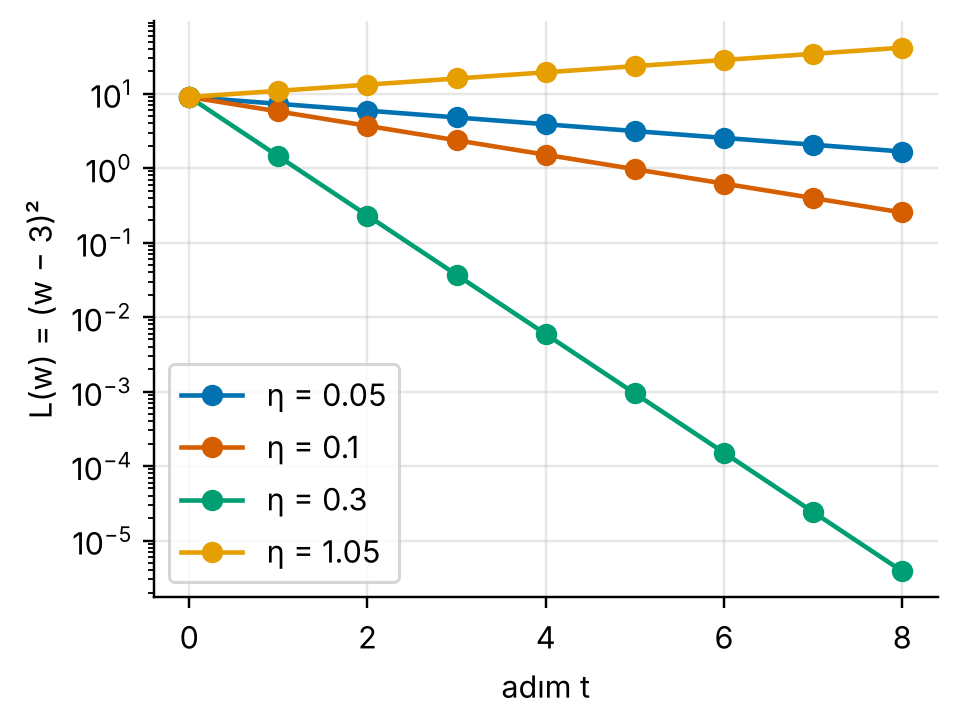

In [6]:
import matplotlib.pyplot as plt
def gi(eta, adim=8, w=0.0):
    yol = [w]
    for _ in range(adim):
        w = w - eta * 2 * (w - 3)   # dL/dw = 2(w - 3)
        yol.append(w)
    return np.array(yol)

plt.figure(figsize=(4.6, 3.4))
for eta in [0.05, 0.1, 0.3, 1.05]:
    yol = gi(eta)
    print(f"η={eta:<5}", yol[:4].round(3))
    plt.plot((yol - 3) ** 2, "o-", label=f"η = {eta}")
plt.yscale("log"); plt.xlabel("adım t")
plt.ylabel("L(w) = (w − 3)²")
plt.legend(); plt.show()

### Alıştırma (Değerlendirme Soruları 8, 9 ve 11)
Önce kâğıt üzerinde çözün, sonra çalıştırıp karşılaştırın.

In [ ]:
# Soru 8: en küçük kareler, MSE ve R²
xa, ya = np.array([2, 4, 6, 8.]), np.array([3, 7, 5, 9.])
wa = np.sum((xa - xa.mean()) * (ya - ya.mean())) / np.sum((xa - xa.mean()) ** 2)
ba = ya.mean() - wa * xa.mean()
sse = np.sum((ya - (wa * xa + ba)) ** 2)
sst = np.sum((ya - ya.mean()) ** 2)
print("S8 : w =", round(wa, 3), " b =", round(ba, 3),
      " MSE =", round(sse / 4, 3), " R² =", round(1 - sse / sst, 3))

# Soru 9: L(w) = (w - 5)², w0 = 1, η = 0.1
w = 1.0
for t in range(3):
    w = w - 0.1 * 2 * (w - 5)
    print("S9 : w", t + 1, "=", round(w, 3))

# Soru 11: normal denklem
Xb = np.array([[1, 0], [1, 1], [1, 2.]]); yb = np.array([1, 2, 4.])
print("S11: [b, w] =", (np.linalg.inv(Xb.T @ Xb) @ Xb.T @ yb).round(3))